In [1]:
import pandas as pd

hotels = pd.read_csv('/kaggle/input/hotels/hotels.csv')
reviews = pd.read_csv('/kaggle/input/hotels/reviews.csv')
users = pd.read_csv('/kaggle/input/hotels/users.csv')

In [2]:
#rename 
hotels_rename = {
    'hotel_id': 'hotel_id',          
    'hotel_name': 'hotel_name',
    'city': 'hotel_city',
    'country': 'hotel_country',     
    'star_rating': 'hotel_star_rating',
    'lat': 'hotel_lat',
    'lon': 'hotel_lon',
    'cleanliness_base': 'hotel_cleanliness_base',
    'comfort_base': 'hotel_comfort_base',
    'facilities_base': 'hotel_facilities_base',
    'location_base': 'hotel_location_base',
    'staff_base': 'hotel_staff_base',
    'value_for_money_base': 'hotel_value_for_money_base'
}

reviews_rename = {
    'review_id': 'review_id',
    'user_id': 'user_id',            
    'hotel_id': 'hotel_id',            
    'review_date': 'review_date',
    'score_overall': 'score_overall',
    'score_cleanliness': 'score_cleanliness',
    'score_comfort': 'score_comfort',
    'score_facilities': 'score_facilities',
    'score_location': 'score_location',
    'score_staff': 'score_staff',
    'score_value_for_money': 'score_value_for_money',
    'review_text': 'review_text'
}

users_rename = {
    'user_id': 'user_id',          
    'user_gender': 'user_gender',
    'country': 'user_country',       
    'age_group': 'user_age_group',
    'traveller_type': 'user_traveller_type',
    'join_date': 'user_join_date'
}

#Apply renames
hotels = hotels.rename(columns=hotels_rename)
reviews = reviews.rename(columns=reviews_rename)
users = users.rename(columns=users_rename)

# quick view of columns after rename
print("hotels cols:", hotels.columns.tolist())
print("reviews cols:", reviews.columns.tolist())
print("users cols:", users.columns.tolist())

hotels cols: ['hotel_id', 'hotel_name', 'hotel_city', 'hotel_country', 'hotel_star_rating', 'hotel_lat', 'hotel_lon', 'hotel_cleanliness_base', 'hotel_comfort_base', 'hotel_facilities_base', 'hotel_location_base', 'hotel_staff_base', 'hotel_value_for_money_base']
reviews cols: ['review_id', 'user_id', 'hotel_id', 'review_date', 'score_overall', 'score_cleanliness', 'score_comfort', 'score_facilities', 'score_location', 'score_staff', 'score_value_for_money', 'review_text']
users cols: ['user_id', 'user_gender', 'user_country', 'user_age_group', 'user_traveller_type', 'user_join_date']


In [3]:
# Merge reviews with users on user_id
reviews_users = pd.merge(
    reviews,
    users,
    on='user_id',
    how='left',  # keep all reviews even if user info missing
    validate='many_to_one'  # many reviews to one user
)


# Merge the result with hotels on hotel_id
merged_df = pd.merge(
    reviews_users,
    hotels,
    on='hotel_id',
    how='left',  # keep all reviews even if hotel info missing
    validate='many_to_one'  # many reviews to one hotel
)

In [4]:
columns_to_drop = [
    'review_text',
    'review_date',
    'user_join_date',
    'hotel_lat',
    'hotel_lon'
]

# Drop the columns
merged_df = merged_df.drop(columns=columns_to_drop)
print(f"Dropped: {columns_to_drop}")
print(f"Dataset shape after dropping columns: {merged_df.shape}")
print(f"Final columns list:\n{merged_df.columns.tolist()}")

Dropped: ['review_text', 'review_date', 'user_join_date', 'hotel_lat', 'hotel_lon']
Dataset shape after dropping columns: (50000, 24)
Final columns list:
['review_id', 'user_id', 'hotel_id', 'score_overall', 'score_cleanliness', 'score_comfort', 'score_facilities', 'score_location', 'score_staff', 'score_value_for_money', 'user_gender', 'user_country', 'user_age_group', 'user_traveller_type', 'hotel_name', 'hotel_city', 'hotel_country', 'hotel_star_rating', 'hotel_cleanliness_base', 'hotel_comfort_base', 'hotel_facilities_base', 'hotel_location_base', 'hotel_staff_base', 'hotel_value_for_money_base']


In [5]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   review_id                   50000 non-null  int64  
 1   user_id                     50000 non-null  int64  
 2   hotel_id                    50000 non-null  int64  
 3   score_overall               50000 non-null  float64
 4   score_cleanliness           50000 non-null  float64
 5   score_comfort               50000 non-null  float64
 6   score_facilities            50000 non-null  float64
 7   score_location              50000 non-null  float64
 8   score_staff                 50000 non-null  float64
 9   score_value_for_money       50000 non-null  float64
 10  user_gender                 50000 non-null  object 
 11  user_country                50000 non-null  object 
 12  user_age_group              50000 non-null  object 
 13  user_traveller_type         500

In [6]:
#new country group column
country_groups_map = {
    'United States': 'North_America', 'Canada': 'North_America',
    'Germany': 'Western_Europe', 'France': 'Western_Europe', 'United Kingdom': 'Western_Europe',
    'Netherlands': 'Western_Europe', 'Spain': 'Western_Europe', 'Italy': 'Western_Europe',
    'Russia': 'Eastern_Europe',
    'China': 'East_Asia', 'Japan': 'East_Asia', 'South Korea': 'East_Asia',
    'Thailand': 'Southeast_Asia', 'Singapore': 'Southeast_Asia',
    'United Arab Emirates': 'Middle_East', 'Turkey': 'Middle_East',
    'Egypt': 'Africa', 'Nigeria': 'Africa', 'South Africa': 'Africa',
    'Australia': 'Oceania', 'New Zealand': 'Oceania',
    'Brazil': 'South_America', 'Argentina': 'South_America',
    'India': 'South_Asia',
    'Mexico': 'North_America_Mexico'
}

# 5.2 Apply the mapping to the 'user_country' column
merged_df['country_group'] = merged_df['hotel_country'].map(country_groups_map)

unmapped_count = merged_df['country_group'].isnull().sum()
print(f"Number of rows with unmapped 'hotel_country' : {unmapped_count}")

Number of rows with unmapped 'hotel_country' : 0


# EDA

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  

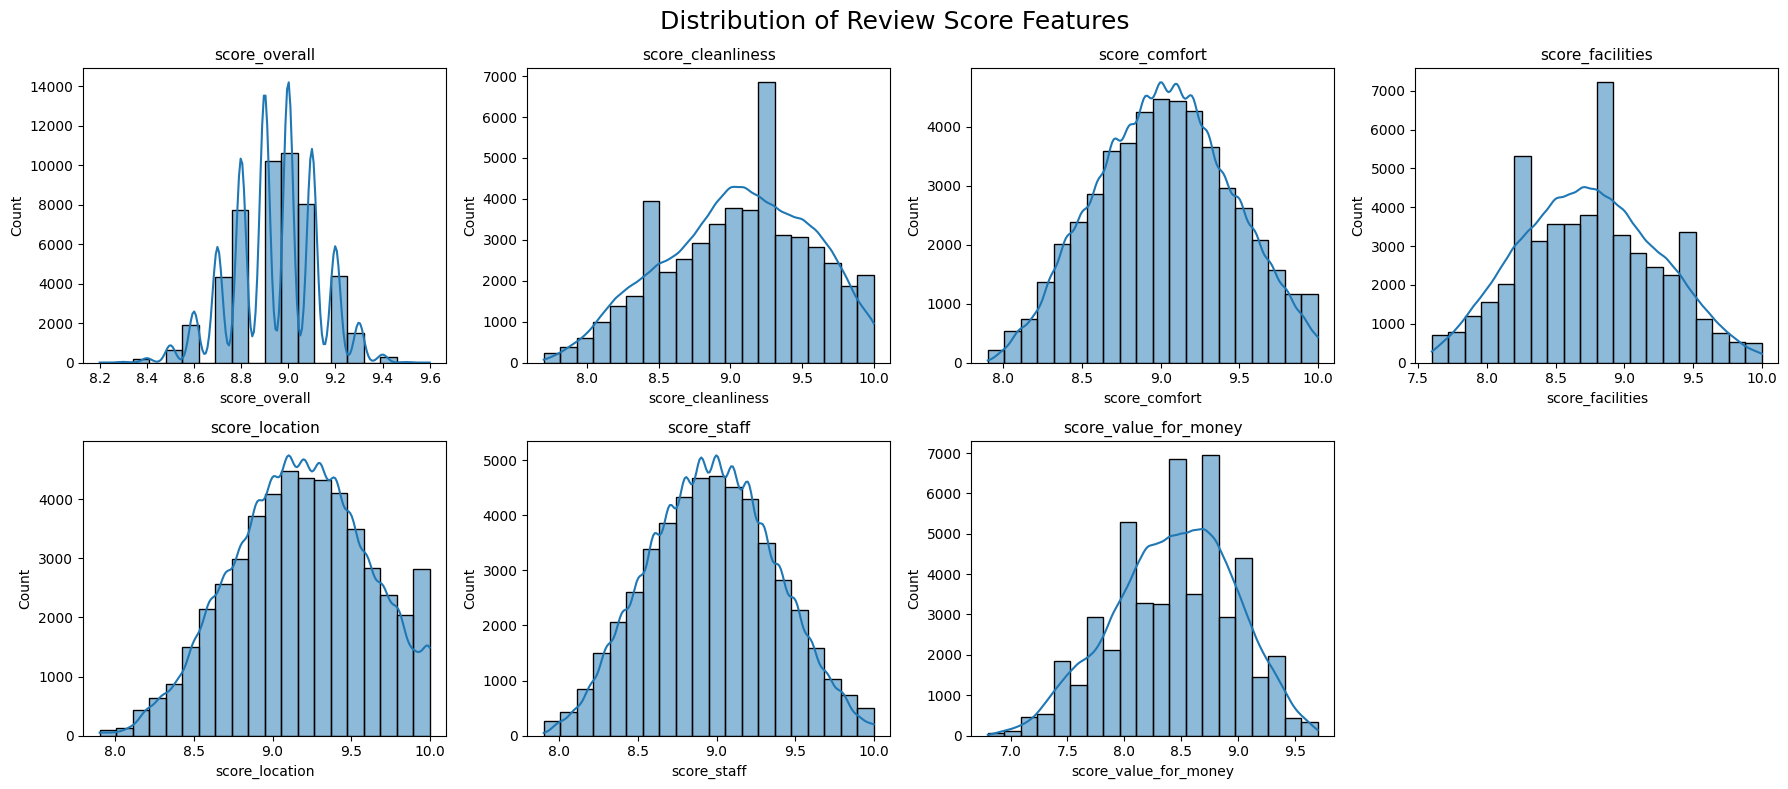

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  

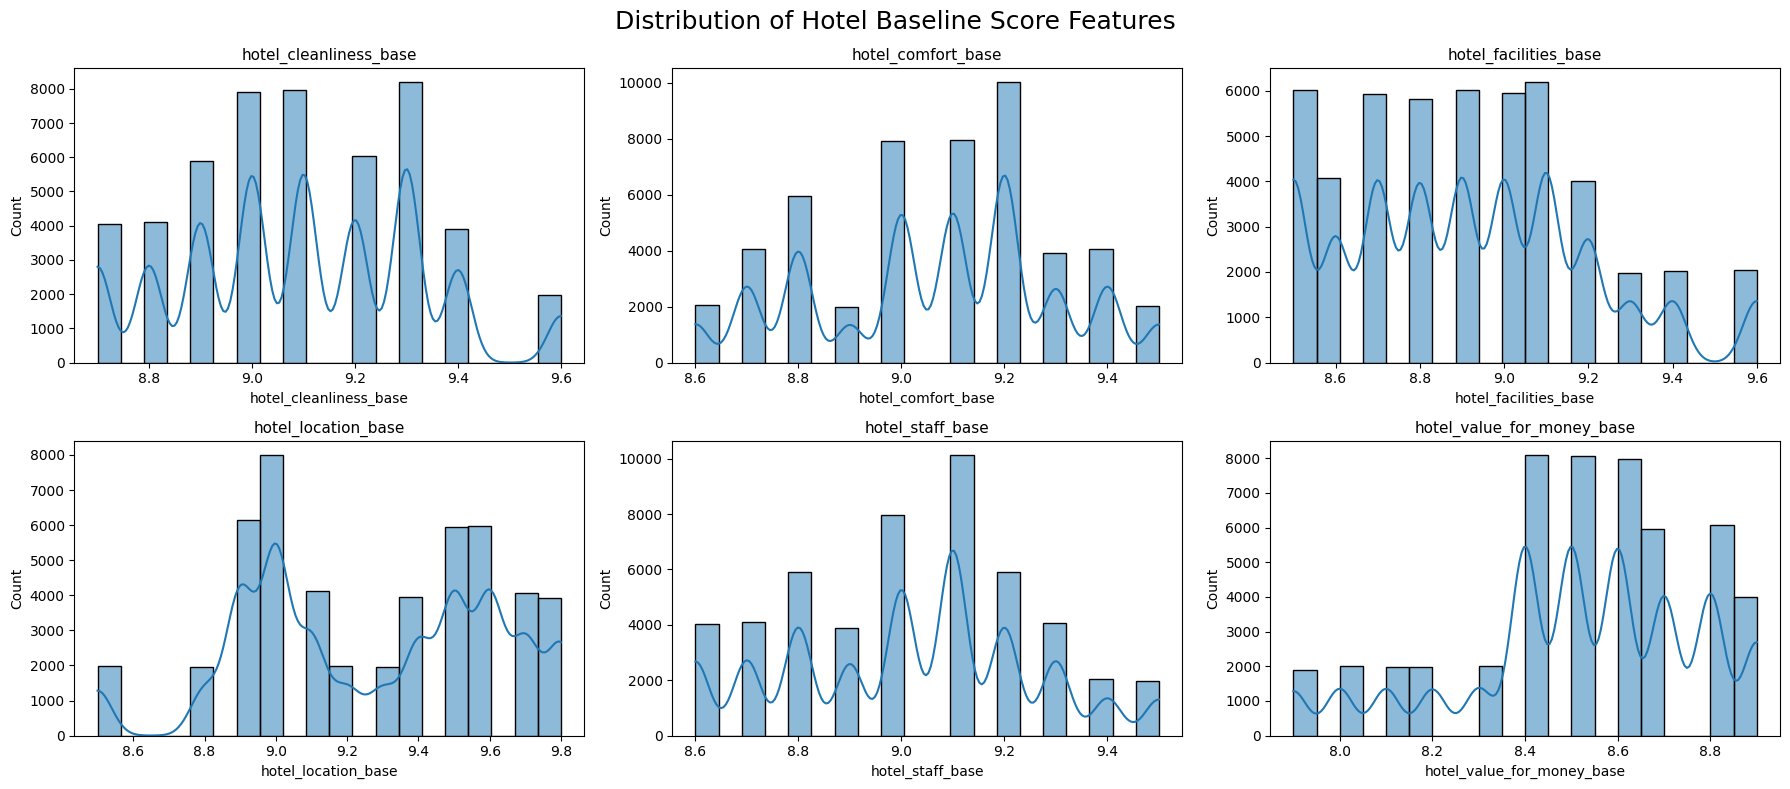

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Split your numerical columns
score_cols = [
    'score_overall', 'score_cleanliness', 'score_comfort',
    'score_facilities', 'score_location', 'score_staff',
    'score_value_for_money'
]

base_cols = [
    'hotel_cleanliness_base', 'hotel_comfort_base', 'hotel_facilities_base',
    'hotel_location_base', 'hotel_staff_base', 'hotel_value_for_money_base'
]

# -----------------------------
# PLOT 1: Review Score Features
# -----------------------------
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(score_cols):
    sns.histplot(merged_df[col], kde=True, bins=20, ax=axes[i])
    axes[i].set_title(f"{col}", fontsize=11)

# Turn off extra subplot (last one is empty since 7 plots in 2x4 grid)
fig.delaxes(axes[-1])

fig.suptitle("Distribution of Review Score Features", fontsize=18)
plt.tight_layout()
plt.show()

# -----------------------------
# PLOT 2: Baseline Score Features
# -----------------------------
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(base_cols):
    sns.histplot(merged_df[col], kde=True, bins=20, ax=axes[i])
    axes[i].set_title(f"{col}", fontsize=11)

fig.suptitle("Distribution of Hotel Baseline Score Features", fontsize=18)
plt.tight_layout()
plt.show()


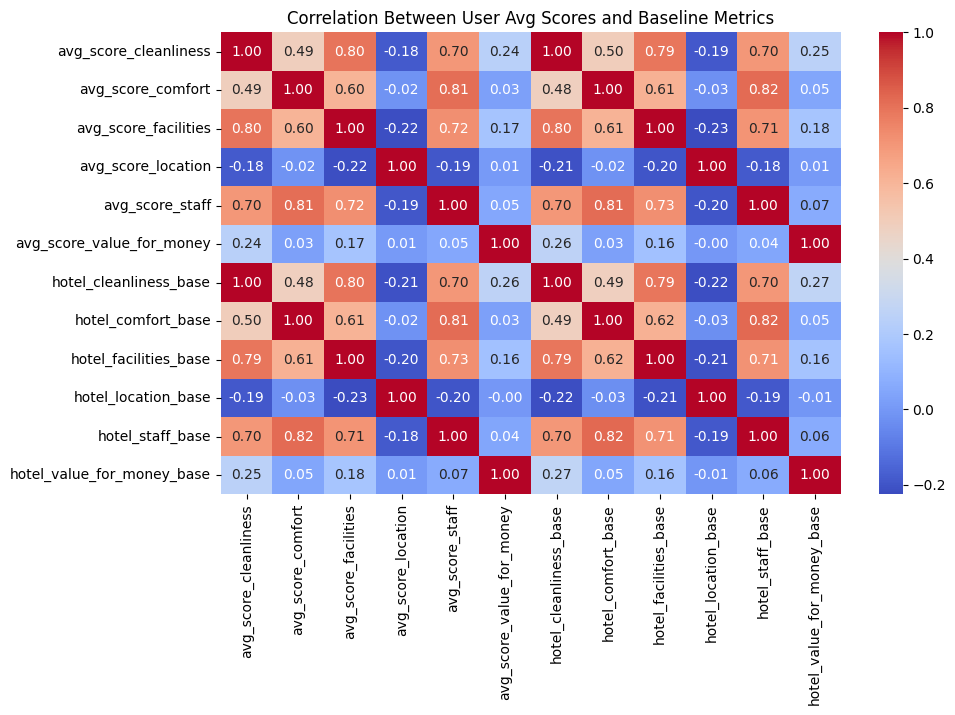

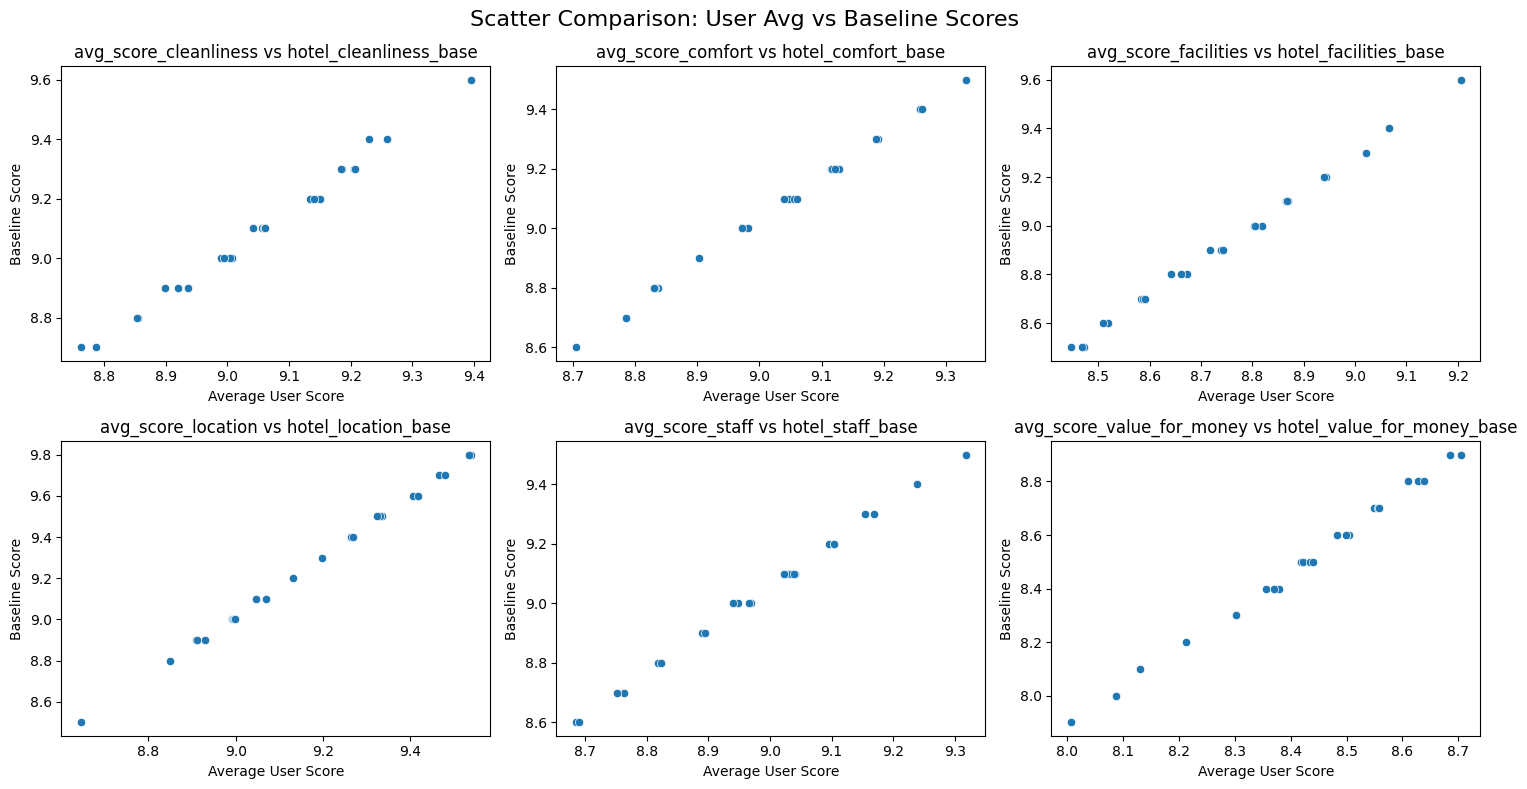


Mean difference between user avg scores and baseline scores:
avg_score_cleanliness - hotel_cleanliness_base: -0.039
avg_score_comfort - hotel_comfort_base: -0.040
avg_score_facilities - hotel_facilities_base: -0.174
avg_score_location - hotel_location_base: -0.094
avg_score_staff - hotel_staff_base: -0.044
avg_score_value_for_money - hotel_value_for_money_base: -0.078


In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ============================
# 1) Compute avg user review scores per hotel
# ============================

user_avg_scores = merged_df.groupby('hotel_id')[
    ['score_cleanliness', 'score_comfort', 'score_facilities',
     'score_location', 'score_staff', 'score_value_for_money']
].mean().reset_index()

user_avg_scores.rename(columns=lambda x: x.replace('score_', 'avg_score_'), inplace=True)

# ============================
# 2) Get baseline scores and merge
# ============================

baseline_scores = merged_df.groupby('hotel_id')[
    ['hotel_cleanliness_base', 'hotel_comfort_base', 'hotel_facilities_base',
     'hotel_location_base', 'hotel_staff_base', 'hotel_value_for_money_base']
].first().reset_index()

comparison_df = pd.merge(user_avg_scores, baseline_scores, on='hotel_id')

# ============================
# 3) Compute differences
# ============================

score_pairs = [
    ('avg_score_cleanliness', 'hotel_cleanliness_base'),
    ('avg_score_comfort', 'hotel_comfort_base'),
    ('avg_score_facilities', 'hotel_facilities_base'),
    ('avg_score_location', 'hotel_location_base'),
    ('avg_score_staff', 'hotel_staff_base'),
    ('avg_score_value_for_money', 'hotel_value_for_money_base')
]

for user_col, base_col in score_pairs:
    comparison_df[user_col.replace('avg_', 'diff_')] = comparison_df[user_col] - comparison_df[base_col]

# ============================
# 4) Correlation Heatmap
# ============================

plt.figure(figsize=(10,6))
corr = comparison_df[[p[0] for p in score_pairs] + [p[1] for p in score_pairs]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between User Avg Scores and Baseline Metrics")
plt.show()

# ============================
# 5) Scatter Plots (NOW SIDE-BY-SIDE)
# ============================

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, (user_col, base_col) in enumerate(score_pairs):
    sns.scatterplot(x=comparison_df[user_col], y=comparison_df[base_col], ax=axes[i])
    axes[i].set_title(f"{user_col} vs {base_col}")
    axes[i].set_xlabel("Average User Score")
    axes[i].set_ylabel("Baseline Score")

plt.suptitle("Scatter Comparison: User Avg vs Baseline Scores", fontsize=16)
plt.tight_layout()
plt.show()


# ============================
# 7) Print avg differences
# ============================

print("\nMean difference between user avg scores and baseline scores:")
for user_col, base_col in score_pairs:
    diff_col = user_col.replace('avg_', 'diff_')
    print(f"{user_col} - {base_col}: {comparison_df[diff_col].mean():.3f}")



# 1. Review Scores Are Very Similar
   - when 'score_cleanliness' is high, 'score_overall' and 'score_comfort' are also high (correlation 0.70 and 0.61).
   - This means users who rate one thing high usually rate everything high.
   - So, these features say almost the same thing. We don’t need all of them.


# 2. Hotel Base Features Are Also Similar
   - 'hotel_staff_base' has a strong link with 'hotel_comfort_base' (0.83) and 'hotel_facilities_base' (0.72).
   - This means good hotels usually have good staff, comfort, and facilities together.
   - These features are very related, so we should combine or  adjust them to avoid repeating the same information.


 (this is called multicollinearity).

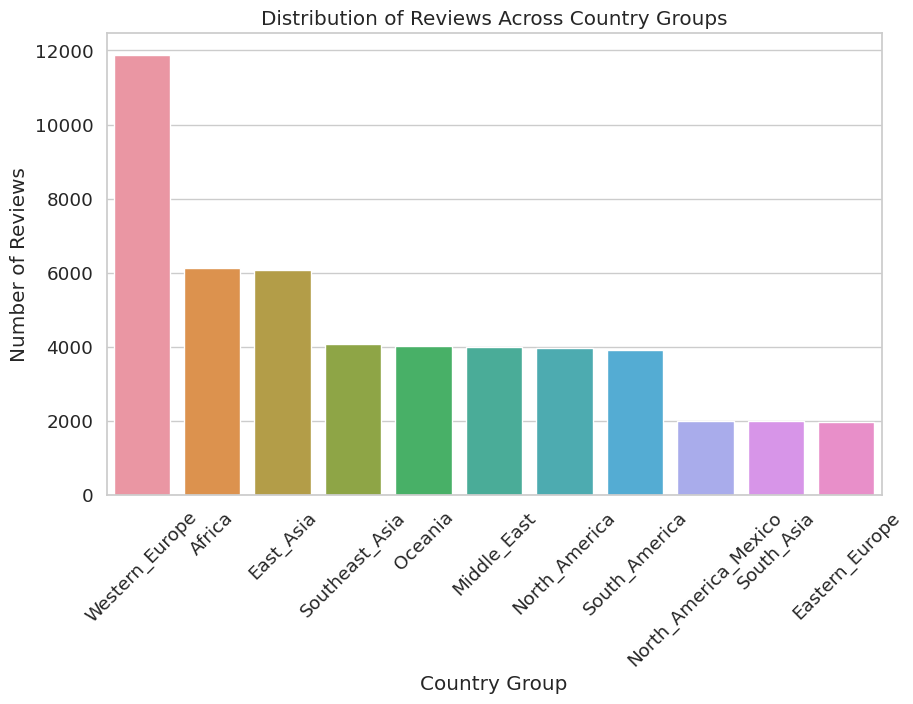

                      Count  Percentage
country_group                          
Western_Europe        11876       23.75
Africa                 6132       12.26
East_Asia              6082       12.16
Southeast_Asia         4070        8.14
Oceania                4014        8.03
Middle_East            3983        7.97
North_America          3962        7.92
South_America          3918        7.84
North_America_Mexico   2004        4.01
South_Asia             1989        3.98
Eastern_Europe         1970        3.94

Class Imbalance Ratio: 6.03


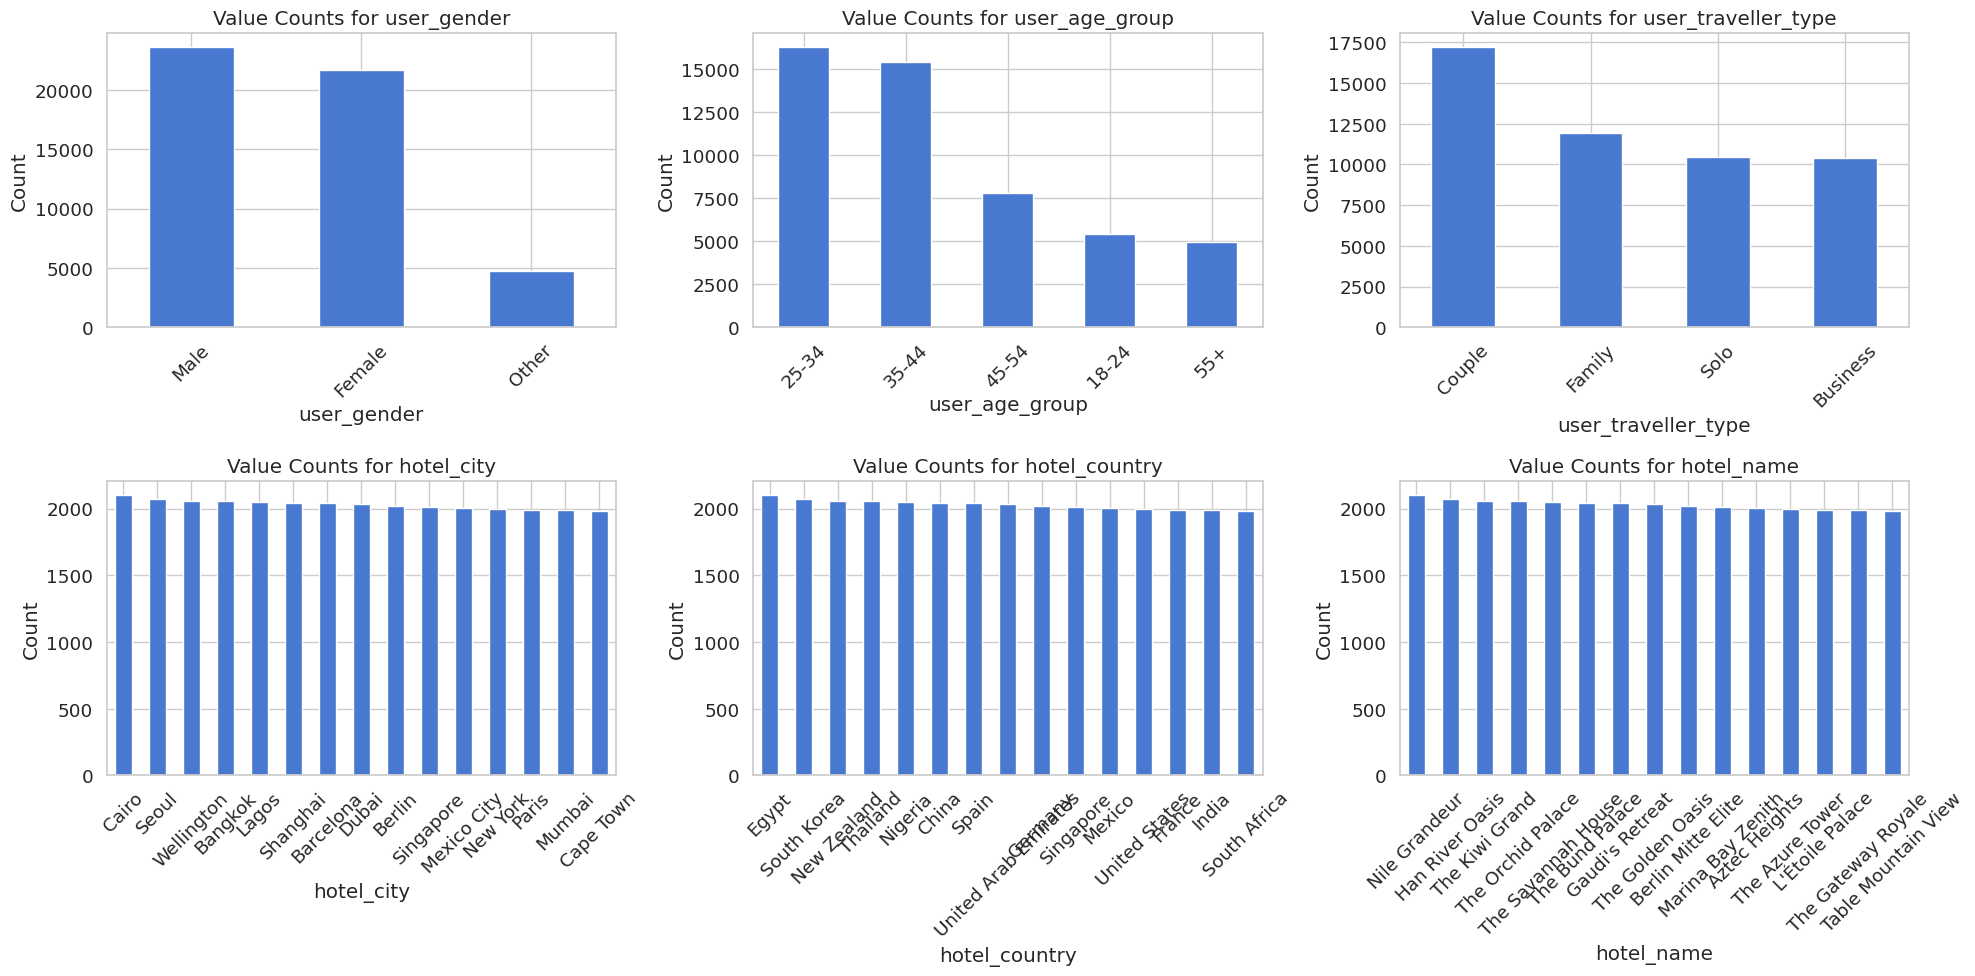

user_gender unique values: 3
user_age_group unique values: 5
user_traveller_type unique values: 4
hotel_city unique values: 25
hotel_country unique values: 25
hotel_name unique values: 25


In [9]:
# ===============================
# Chapter 3: Exploratory Data Analysis (EDA) - Categorical Focus
# ===============================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid", palette="muted", font_scale=1.2)


target_counts = merged_df['country_group'].value_counts()
target_percent = target_counts / len(merged_df) * 100

plt.figure(figsize=(10,6))
sns.countplot(data=merged_df, x='country_group', order=target_counts.index)
plt.title("Distribution of Reviews Across Country Groups")
plt.xticks(rotation=45)
plt.ylabel("Number of Reviews")
plt.xlabel("Country Group")
plt.show()

summary_df = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percent.round(2)
})

print(summary_df)
print(f"\nClass Imbalance Ratio: {(target_counts.max()/target_counts.min()):.2f}")



# -------------------------------
# 3.3 Univariate Analysis (Categorical) - MULTIPLE PLOTS IN GRID
# -------------------------------

categorical_cols = [
    'user_gender', 'user_age_group', 'user_traveller_type',
    'hotel_city', 'hotel_country', 'hotel_name'
]

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
axes = axes.flatten()

for ax, col in zip(axes, categorical_cols):
    merged_df[col].value_counts().head(15).plot(kind='bar', ax=ax)
    ax.set_title(f"Value Counts for {col}")
    ax.set_ylabel("Count")
    ax.set_xlabel(col)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

for col in categorical_cols:
    print(f"{col} unique values:", merged_df[col].nunique())


# DATA ENGINEERING QUESTIONS

# Question 1: Which city is best for each traveler type?

In [10]:
print("different travel types:" , merged_df['user_traveller_type'].unique())
print("-------------------------")
print("different cities:" ,merged_df['hotel_city'].unique())

different travel types: ['Solo' 'Couple' 'Business' 'Family']
-------------------------
different cities: ['New York' 'Tokyo' 'Cairo' 'Barcelona' 'Moscow' 'Sydney' 'Buenos Aires'
 'Singapore' 'Mumbai' 'Cape Town' 'Berlin' 'Wellington' 'Paris' 'Shanghai'
 'Lagos' 'London' 'Bangkok' 'Istanbul' 'Mexico City' 'Toronto' 'Dubai'
 'Seoul' 'Amsterdam' 'Rome' 'Rio de Janeiro']


In [11]:
#group reviews by traveler type and city
#calculate the average score overall score for each group
#remove the grouping index back to normal index
city_scores = merged_df.groupby(['user_traveller_type', 'hotel_city'])['score_overall'].mean().reset_index()
city_scores.head()

,user_traveller_type,hotel_city,score_overall
0,Business,Amsterdam,8.964348
1,Business,Bangkok,8.886265
2,Business,Barcelona,8.904545
3,Business,Berlin,8.868122
4,Business,Buenos Aires,8.690000


In [12]:
#find the row with the highest score for each traveler type.
best_city_per_type = city_scores.loc[city_scores.groupby('user_traveller_type')['score_overall'].idxmax()]

In [13]:
best_city_per_type

,user_traveller_type,hotel_city,score_overall
7,Business,Dubai,8.965668
25,Couple,Amsterdam,9.096989
57,Family,Dubai,9.214381
75,Solo,Amsterdam,9.108454


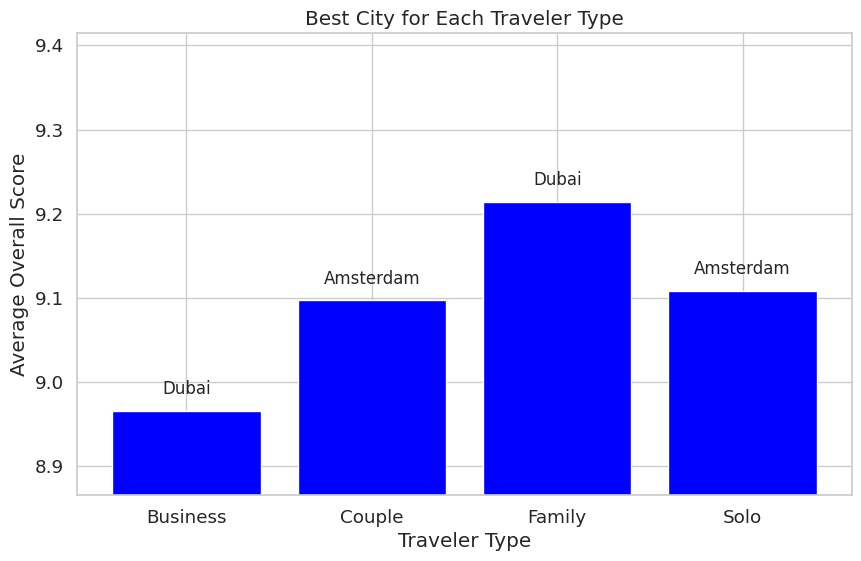

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.bar(best_city_per_type['user_traveller_type'], 
        best_city_per_type['score_overall'], 
        color='blue')


for i, (traveler, city, score) in enumerate(zip(best_city_per_type['user_traveller_type'], 
                                                best_city_per_type['hotel_city'], 
                                                best_city_per_type['score_overall'])):
    plt.text(i, score + 0.02, city, ha='center', fontsize=12)

plt.xlabel("Traveler Type")
plt.ylabel("Average Overall Score")
plt.title("Best City for Each Traveler Type")
plt.ylim(best_city_per_type['score_overall'].min() - 0.1, 
         best_city_per_type['score_overall'].max() + 0.2)
plt.show()

Dubai performs best for both Family travelers (with the highest score overall at $9.21$) and Business travelers.

Amsterdam is the preferred city for Couple and Solo travelers, both earning very high average scores over $9.0$.

# Question 2: Top 3 Countries with Best Value-for-Money per Age Group

In [15]:
print(merged_df['user_age_group'].unique())

['25-34' '35-44' '55+' '45-54' '18-24']


In [16]:
#group age group with country
#get the average score value for money
#reset index
avg_value = merged_df.groupby(['user_age_group', 'hotel_country'])['score_value_for_money'].mean().reset_index()

In [17]:
#sort age group ascending but score value for money in descending
#get top 3
avg_value = avg_value.sort_values(['user_age_group', 'score_value_for_money'], ascending=[True, False])
top3 = avg_value.groupby('user_age_group').head(3) 
top3

,user_age_group,hotel_country,score_value_for_money
4,18-24,China,8.706926
12,18-24,Netherlands,8.704911
3,18-24,Canada,8.661261
29,25-34,China,8.727941
37,25-34,Netherlands,8.683442
44,25-34,Spain,8.625074
54,35-44,China,8.700799
62,35-44,Netherlands,8.693268
63,35-44,New Zealand,8.646429
79,45-54,China,8.722112


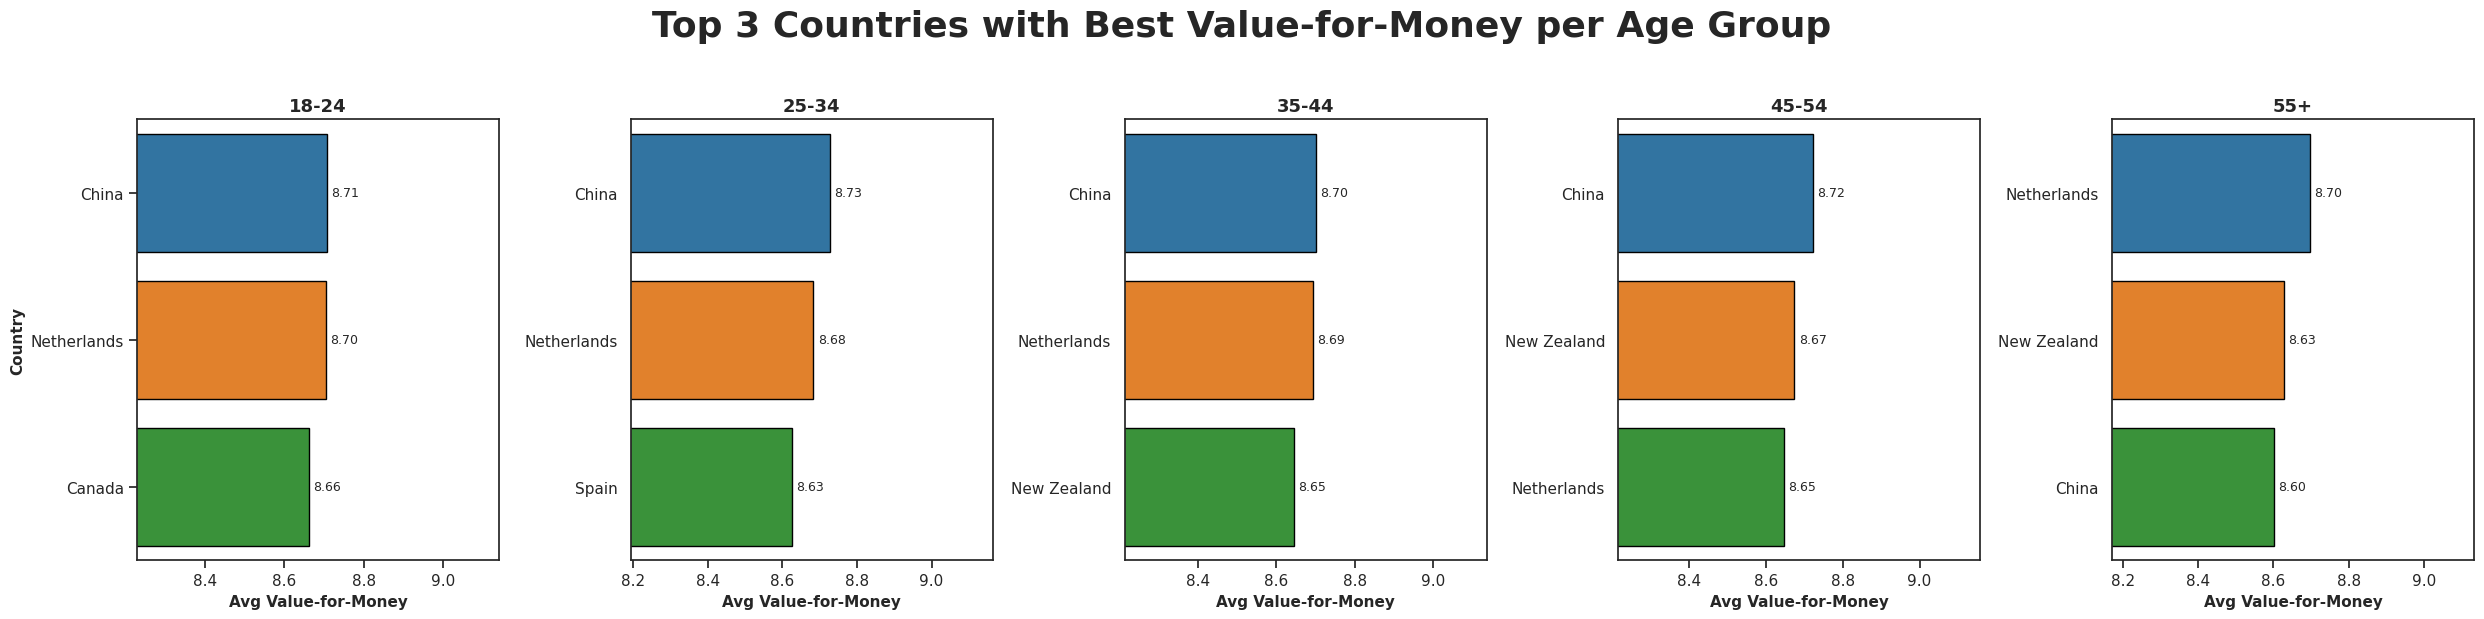

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.set(style="ticks") 


age_groups = top3['user_age_group'].unique()

# create one plot for each age group
plt.figure(figsize=(5 * len(age_groups), 6))

for i, group in enumerate(age_groups, start=1):
    # filter only this age group
    group_data = top3[top3['user_age_group'] == group].sort_values(
        by='score_value_for_money', ascending=False
    )

    # a subplot
    plt.subplot(1, len(age_groups), i)


    sns.barplot(
        data=group_data,
        y='hotel_country',
        x='score_value_for_money',
        palette='tab10',  # bright colors
        edgecolor='black'
    )


    plt.title(f'{group}', fontsize=13, fontweight='bold')
    plt.xlabel('Avg Value-for-Money', fontsize=11, fontweight='bold')

    # only show y label on first plot
    if i == 1:
        plt.ylabel('Country', fontsize=11 , fontweight='bold')
    else:
        plt.ylabel('')
        plt.tick_params(axis='y', left=False)

    # add numbers on bars
    for container in plt.gca().containers:
        plt.bar_label(container, fmt='%.2f', fontsize=9, padding=3)

    # zoom in on the range to exaggerate differences
    min_score = group_data['score_value_for_money'].min()
    max_score = group_data['score_value_for_money'].max()
    plt.xlim(min_score * 0.95, max_score * 1.05)

plt.suptitle('Top 3 Countries with Best Value-for-Money per Age Group', 
             fontsize=26, fontweight='bold', y=1.03)

plt.tight_layout()
plt.show()

In [19]:
DATASET = 'merged_df.csv'
merged_df.to_csv(DATASET, index=False)

In [20]:

merged_df["hotel_score"] = merged_df[
    ["hotel_staff_base", "hotel_comfort_base", "hotel_facilities_base",
     "hotel_cleanliness_base", "hotel_value_for_money_base",'hotel_location_base']
].mean(axis=1)

In [21]:
print(merged_df[['hotel_score', 'score_overall']].head(10))


   hotel_score  score_overall
0     8.816667            8.7
1     9.016667            9.1
2     8.716667            8.8
3     9.116667            8.9
4     9.016667            9.1
5     8.916667            8.7
6     8.816667            8.9
7     9.133333            8.8
8     8.833333            8.8
9     9.016667            8.8


hotel_score = score_overall in some hotels

# encoding

In [22]:
pip install category-encoders

Note: you may need to restart the kernel to use updated packages.


In [23]:
# merged_df.drop(
#     columns=[
#         "hotel_staff_base", 
#         "hotel_comfort_base", 
#         "hotel_facilities_base",
#         "hotel_cleanliness_base", 
#         "hotel_value_for_money_base",
#         "score_cleanliness",
#         "score_comfort",
#         "score_facilities",
#         "score_location",
#         "score_staff",
#         "score_value_for_money",
#         'review_id',
#         'user_id',
#         'hotel_id',
#         'hotel_location_base',
#         'user_country',
#         'hotel_name' ,
#         'hotel_star_rating',
#         'hotel_country'
#     ],
#     inplace=True
# )

In [24]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Define columns to keep before splitting
features_to_use = [ 'user_gender', 'user_age_group', 'user_traveller_type']

# Keep the columns needed for aggregation
aggregation_cols = [
    #'hotel_staff_base', 'hotel_comfort_base', 'hotel_facilities_base',
     #               'hotel_cleanliness_base', 'hotel_value_for_money_base',
                    'score_cleanliness', 'score_comfort', 'score_facilities',
                    'score_location', 'score_staff', 'score_value_for_money' 
                   ]

# Prepare X and y WITHOUT dropping columns yet
X = merged_df[aggregation_cols + features_to_use ].copy()
y = merged_df['hotel_country'].copy()

print("Dataset shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())
print(f"\nNumber of classes: {y.nunique()}")

2025-10-22 23:25:02.205481: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1761175502.476474      13 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1761175502.554429      13 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Dataset shape: (50000, 9)

Target distribution:
hotel_country
Egypt                   2104
South Korea             2071
New Zealand             2060
Thailand                2055
Nigeria                 2049
China                   2040
Spain                   2039
United Arab Emirates    2035
Germany                 2022
Singapore               2015
Mexico                  2004
United States           1998
France                  1993
India                   1989
South Africa            1979
Japan                   1971
Italy                   1971
Russia                  1970
Canada                  1964
Brazil                  1962
Argentina               1956
Australia               1954
Netherlands             1949
Turkey                  1948
United Kingdom          1902
Name: count, dtype: int64

Number of classes: 25


In [25]:
# ============================================================
# 2. TRAIN-TEST SPLIT FIRST (CRITICAL FOR AVOIDING LEAKAGE)
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTrain size: {X_train.shape}")
print(f"Test size: {X_test.shape}")


Train size: (40000, 9)
Test size: (10000, 9)


In [26]:
print("CALCULATING AGGREGATED FEATURES (NO LEAKAGE)")

hotel_score_cols = [
    'score_cleanliness',      # This review's cleanliness rating
    'score_comfort',          # This review's comfort rating  
    'score_facilities',       # This review's facilities rating
    'score_location',         # This review's location rating
    'score_staff',            # This review's staff rating
    'score_value_for_money'   # This review's value rating
]

# X_train['hotel_score'] = X_train[hotel_score_cols].mean(axis=1)
# X_test['hotel_score'] = X_test[hotel_score_cols].mean(axis=1)

# #Calculate score_overall_agg as average of score_* columns
# score_cols = ['score_cleanliness', 'score_comfort', 'score_facilities',
#              'score_location', 'score_staff', 'score_value_for_money']

# X_train['score_overall_agg'] = X_train[score_cols].mean(axis=1)
# X_test['score_overall_agg'] = X_test[score_cols].mean(axis=1)

print("Aggregated features calculated separately for train and test")

CALCULATING AGGREGATED FEATURES (NO LEAKAGE)
Aggregated features calculated separately for train and test


In [27]:
# columns_to_drop = hotel_score_cols #+ score_cols

# X_train.drop(columns=columns_to_drop, inplace=True)
# X_test.drop(columns=columns_to_drop, inplace=True)

# print(f"✓ Dropped aggregation columns")
# print(f"Final features: {list(X_train.columns)}")

In [28]:
# ============================================================
# 5. ENCODE CATEGORICAL FEATURES (FIT ON TRAIN ONLY)
# ============================================================

print("\n" + "="*60)
print("ENCODING FEATURES")
print("="*60)

#One-Hot Encoding: user_gender
X_train = pd.get_dummies(X_train, columns=['user_gender'], prefix='gender', drop_first=True)
X_test = pd.get_dummies(X_test, columns=['user_gender'], prefix='gender', drop_first=True)

#Ordinal Encoding: user_age_group
age_mapping = {'18-24': 0, '25-34': 1, '35-44': 2, '45-54': 3, '55+': 4}
X_train['user_age_group'] = X_train['user_age_group'].map(age_mapping)
X_test['user_age_group'] = X_test['user_age_group'].map(age_mapping)

#One-Hot Encoding: user_traveller_type
X_train = pd.get_dummies(X_train, columns=['user_traveller_type'], drop_first=True)
X_test = pd.get_dummies(X_test, columns=['user_traveller_type'], drop_first=True)

# Align columns (ensure test has same columns as train)
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

print(f"✓ Features after encoding: {X_train.shape[1]}")


ENCODING FEATURES
✓ Features after encoding: 12


In [29]:
X_train.columns

Index(['score_cleanliness', 'score_comfort', 'score_facilities',
       'score_location', 'score_staff', 'score_value_for_money',
       'user_age_group', 'gender_Male', 'gender_Other',
       'user_traveller_type_Couple', 'user_traveller_type_Family',
       'user_traveller_type_Solo'],
      dtype='object')

In [30]:
# ============================================================
# 6. SCALE FEATURES (FIT ON TRAIN ONLY, TRANSFORM BOTH)
# ============================================================

print("\nScaling features...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # Fit on train only
X_test_scaled = scaler.transform(X_test)        # Transform test using train stats

print(f"✓ Features after scaling: {X_train_scaled.shape[1]}")


Scaling features...
✓ Features after scaling: 12


In [31]:
# ============================================================
# 7. ENCODE TARGET VARIABLE (FIT ON TRAIN ONLY)
# ============================================================


print("\nEncoding target variable...")
le_target = LabelEncoder()
y_train_encoded = le_target.fit_transform(y_train)  # Fit on train only
y_test_encoded = le_target.transform(y_test)

# Convert to categorical (one-hot encoding for neural network)
n_classes = len(le_target.classes_)
y_train_categorical = to_categorical(y_train_encoded, num_classes=n_classes)
y_test_categorical = to_categorical(y_test_encoded, num_classes=n_classes)

print(f"Number of classes: {n_classes}")
print(f"Classes: {le_target.classes_}")
print(f"Target shape: {y_train_categorical.shape}")

print("\n" + "="*60)
print("DATA PREPARATION COMPLETE - NO DATA LEAKAGE")
print("="*60)
print("\n✓ Train-test split performed BEFORE aggregation")
print("✓ Aggregates calculated independently on train and test")
print("✓ Scaling fitted on training data only")
print("✓ Encoding fitted on training data only")


Encoding target variable...
Number of classes: 25
Classes: ['Argentina' 'Australia' 'Brazil' 'Canada' 'China' 'Egypt' 'France'
 'Germany' 'India' 'Italy' 'Japan' 'Mexico' 'Netherlands' 'New Zealand'
 'Nigeria' 'Russia' 'Singapore' 'South Africa' 'South Korea' 'Spain'
 'Thailand' 'Turkey' 'United Arab Emirates' 'United Kingdom'
 'United States']
Target shape: (40000, 25)

DATA PREPARATION COMPLETE - NO DATA LEAKAGE

✓ Train-test split performed BEFORE aggregation
✓ Aggregates calculated independently on train and test
✓ Scaling fitted on training data only
✓ Encoding fitted on training data only


In [32]:
# BUILD NEURAL NETWORK MODEL

# Get input dimension
input_dim = X_train_scaled.shape[1]

# Build model
model = models.Sequential([
    layers.Dense(128, activation='relu', input_dim=input_dim, name='hidden_layer_1'),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu', name='hidden_layer_2'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu', name='hidden_layer_3'),
    layers.Dense(n_classes, activation='softmax', name='output_layer')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-10-22 23:25:16.184078: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [33]:
#TRAIN THE MODEL

# Define callbacks
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# Train model
history = model.fit(
    X_train_scaled, y_train_categorical,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=early_stopping,
    verbose=1
)

Epoch 1/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.1117 - loss: 2.9434 - val_accuracy: 0.2096 - val_loss: 2.4450
Epoch 2/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2059 - loss: 2.4994 - val_accuracy: 0.2214 - val_loss: 2.3912
Epoch 3/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2133 - loss: 2.4384 - val_accuracy: 0.2234 - val_loss: 2.3515
Epoch 4/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2210 - loss: 2.4049 - val_accuracy: 0.2364 - val_loss: 2.3237
Epoch 5/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2230 - loss: 2.3605 - val_accuracy: 0.2296 - val_loss: 2.2923
Epoch 6/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2284 - loss: 2.3307 - val_accuracy: 0.2290 - val_loss: 2.2628
Epoch 7/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2281 - loss: 2.3135 - val_accuracy: 0.2356 - val_loss: 2.2354
Epoch 8/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2348 - loss: 2

In [34]:
#EVALUATE THE MODEL

# Evaluate on test set
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test_categorical, verbose=0)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Make predictions
y_pred_proba = model.predict(X_test_scaled)
y_pred = np.argmax(y_pred_proba, axis=1)

# Classification report
print("CLASSIFICATION REPORT")
print(classification_report(y_test_encoded, y_pred, target_names=le_target.classes_))



Test Loss: 1.9831
Test Accuracy: 0.2790
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
CLASSIFICATION REPORT
                      precision    recall  f1-score   support

           Argentina       0.23      0.29      0.26       391
           Australia       0.44      0.33      0.38       391
              Brazil       0.18      0.49      0.26       392
              Canada       0.33      0.36      0.35       393
               China       0.30      0.19      0.23       408
               Egypt       0.19      0.19      0.19       421
              France       0.54      0.43      0.48       398
             Germany       0.15      0.05      0.08       404
               India       0.09      0.04      0.05       398
               Italy       0.27      0.25      0.26       394
               Japan       0.74      0.65      0.69       394
              Mexico       0.38      0.10      0.16       401
         Netherlands       0.38      0.32      0.34       390
         New Zealand       

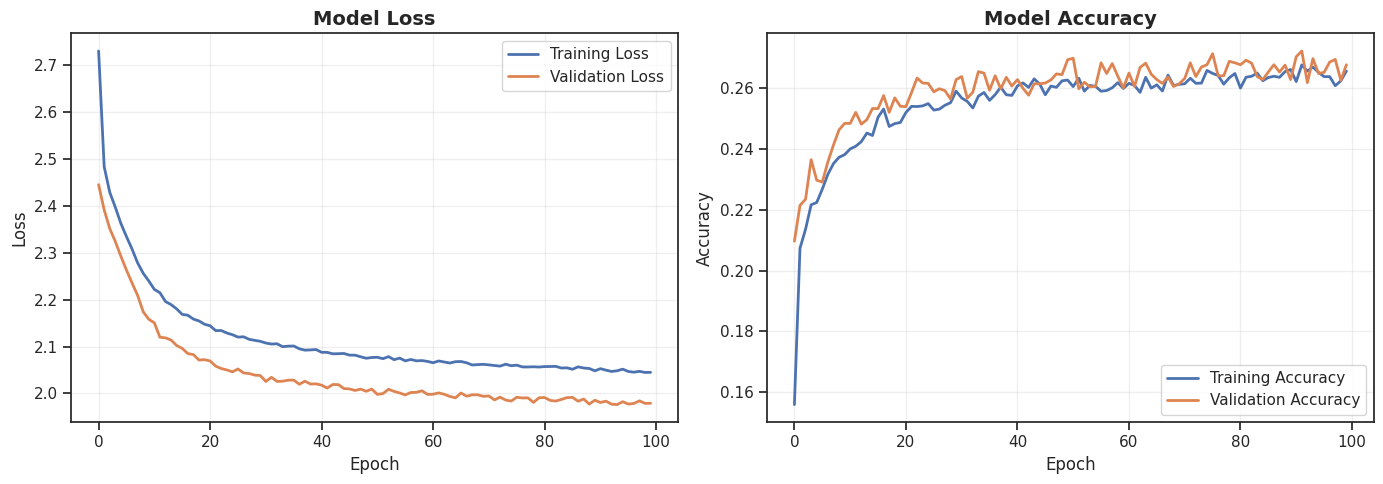

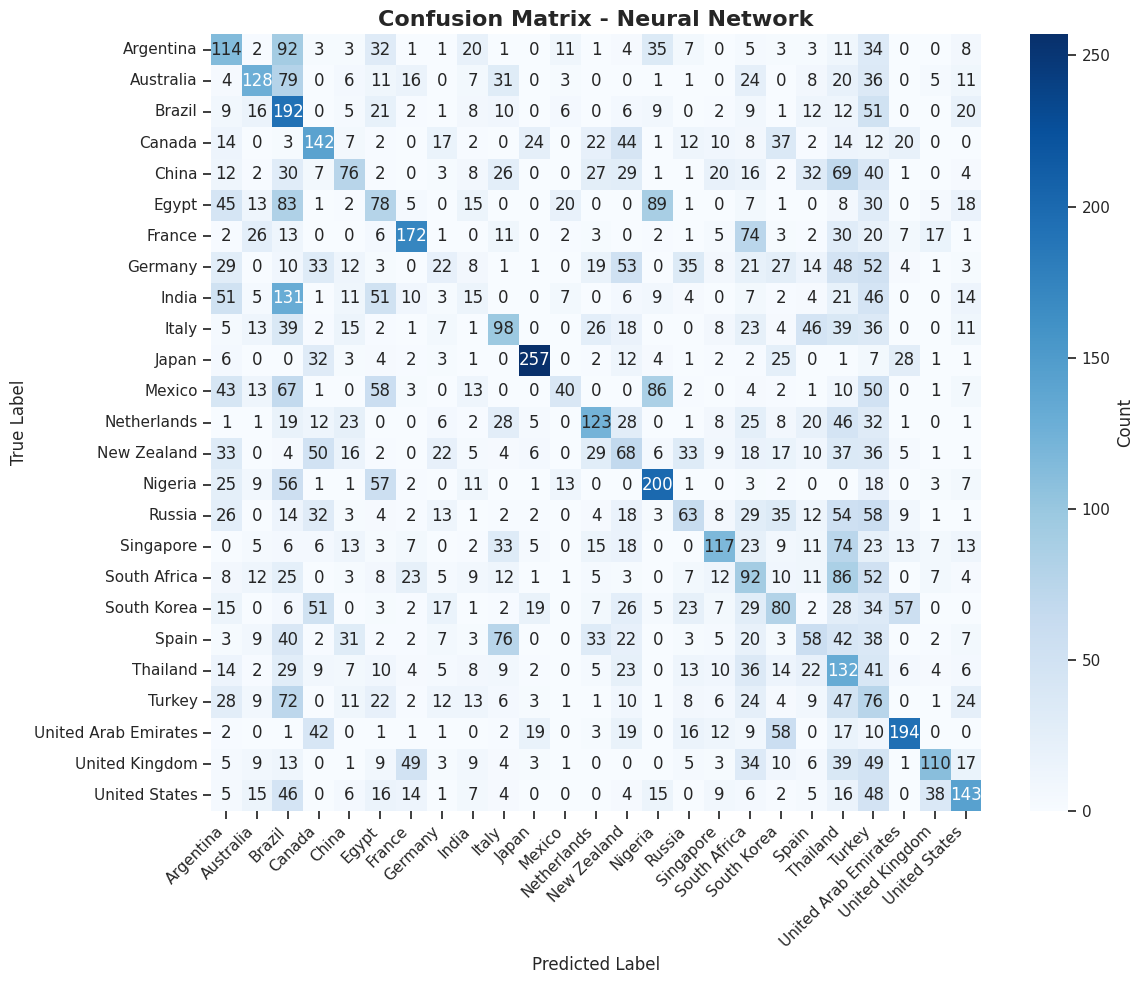

In [35]:
# VISUALIZATIONS

# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
axes[0].plot(history.history['loss'], label='Training Loss', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0].set_title('Model Loss', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy plot
axes[1].plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
axes[1].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
axes[1].set_title('Model Accuracy', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
#plt.savefig('training_history.png', dpi=300, bbox_inches='tight')
plt.show()

# Confusion Matrix
plt.figure(figsize=(12, 10))
cm = confusion_matrix(y_test_encoded, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le_target.classes_, 
            yticklabels=le_target.classes_,
            cbar_kws={'label': 'Count'})
plt.title('Confusion Matrix - Neural Network', fontsize=16, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
#plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


  0%|          | 0/50 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 6s 918us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 6s 931us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 6s 946us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 6s 949us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 6s 892us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 6s 988us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 6s 889us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 6s 960us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 6s 968us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 6s 951us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 6s 980us/step
1/1 ━━

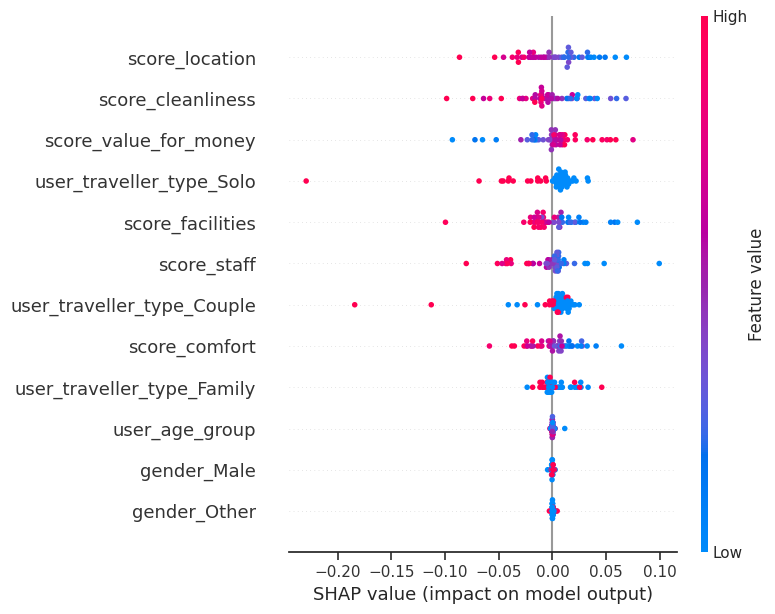

In [36]:
import shap
import numpy as np

# Select a small background sample for speed
background = X_train_scaled[np.random.choice(X_train_scaled.shape[0], 100, replace=False)]

# KernelExplainer for tabular Keras models
explainer = shap.KernelExplainer(model.predict, background)

# Compute SHAP for a subset of test data
X_shap = X_test_scaled[:50]  # prevent long runtime
shap_values = explainer.shap_values(X_shap)

feature_names = X_train.columns.tolist()

# Summary Plot for Class 0
shap.summary_plot(shap_values[0], X_shap, feature_names=feature_names)



In [37]:
import shap
import numpy as np
import pandas as pd

index = 7

# ---- Select sample WITH FEATURE NAMES ----
sample = pd.DataFrame(X_test_scaled[index:index+1], columns=X_test.columns)

# ---- True Label ----
true_class_name = y_test.iloc[index]

# ---- Prediction ----
probs = model.predict(sample)[0]
pred_class_index = np.argmax(probs)
pred_class_name = le_target.inverse_transform([pred_class_index])[0]

# ---- Print Real vs Predicted ----
print(f"Sample Index: {index}")
print(f"✔ True Label      : {true_class_name}")
print(f"✔ Predicted Label : {pred_class_name}")
print(f"✔ Class Probabilities: {probs}")

# ---- SHAP Force Plot ----
shap.initjs()
class_shap_values = shap_values[pred_class_index][index]

shap.force_plot(
    explainer.expected_value[pred_class_index],
    class_shap_values,
    sample  # <--- NOW SHAP CAN DISPLAY FEATURE NAMES
)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Sample Index: 7
✔ True Label      : Germany
✔ Predicted Label : Singapore
✔ Class Probabilities: [7.1709981e-04 1.5144708e-03 9.4567979e-05 7.0044003e-02 3.5741694e-02
 7.7135828e-06 2.5081519e-02 7.6548830e-02 2.6853598e-04 5.8471579e-02
 9.2711682e-03 7.6314200e-06 8.4413201e-02 7.8959063e-02 1.1207201e-08
 6.5381132e-02 9.2924751e-02 7.0550911e-02 7.6472588e-02 6.3939497e-02
 8.0606475e-02 1.2834248e-02 6.1695535e-02 3.4015957e-02 4.3780534e-04]


In [38]:
import shap
import numpy as np
import pandas as pd

index = 0

# ---- Select sample WITH FEATURE NAMES ----
sample = pd.DataFrame(X_test_scaled[index:index+1], columns=X_test.columns)

# ---- True Label ----
true_class_name = y_test.iloc[index]

# ---- Prediction ----
probs = model.predict(sample)[0]
pred_class_index = np.argmax(probs)
pred_class_name = le_target.inverse_transform([pred_class_index])[0]

# ---- Print Real vs Predicted ----
print(f"Sample Index: {index}")
print(f"✔ True Label      : {true_class_name}")
print(f"✔ Predicted Label : {pred_class_name}")
print(f"✔ Class Probabilities: {probs}")

# ---- SHAP Force Plot ----
shap.initjs()
class_shap_values = shap_values[pred_class_index][index]

shap.force_plot(
    explainer.expected_value[pred_class_index],
    class_shap_values,
    sample  # <--- NOW SHAP CAN DISPLAY FEATURE NAMES
)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Sample Index: 0
✔ True Label      : Italy
✔ Predicted Label : Spain
✔ Class Probabilities: [3.9426790e-04 1.0843294e-03 5.5761550e-02 2.6361556e-07 1.0563702e-01
 2.7003360e-05 5.2278483e-05 3.3327941e-02 3.0970655e-03 1.4821073e-01
 5.1883120e-09 5.2919265e-08 3.6779076e-02 1.0589751e-02 3.4178989e-11
 3.5522517e-03 9.9615358e-02 1.0497821e-02 5.3562931e-06 1.7229885e-01
 4.0937107e-02 9.6109584e-02 1.0986035e-06 4.6940316e-02 1.3508084e-01]


In [39]:
import shap
import numpy as np
import pandas as pd

index = 1

# ---- Select sample WITH FEATURE NAMES ----
sample = pd.DataFrame(X_test_scaled[index:index+1], columns=X_test.columns)

# ---- True Label ----
true_class_name = y_test.iloc[index]

# ---- Prediction ----
probs = model.predict(sample)[0]
pred_class_index = np.argmax(probs)
pred_class_name = le_target.inverse_transform([pred_class_index])[0]

# ---- Print Real vs Predicted ----
print(f"Sample Index: {index}")
print(f"✔ True Label      : {true_class_name}")
print(f"✔ Predicted Label : {pred_class_name}")
print(f"✔ Class Probabilities: {probs}")

# ---- SHAP Force Plot ----
shap.initjs()
class_shap_values = shap_values[pred_class_index][index]

shap.force_plot(
    explainer.expected_value[pred_class_index],
    class_shap_values,
    sample  # <--- NOW SHAP CAN DISPLAY FEATURE NAMES
)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Sample Index: 1
✔ True Label      : South Africa
✔ Predicted Label : France
✔ Class Probabilities: [8.5134292e-05 1.6819677e-01 9.4549693e-03 4.6531288e-18 5.5416141e-21
 1.4282092e-01 2.3028530e-01 3.2364696e-06 6.5224818e-03 1.2931306e-04
 7.2578979e-07 5.1583990e-02 2.0490655e-14 1.1784283e-15 1.6039744e-01
 1.0595169e-03 6.0475382e-11 8.6698219e-02 1.6788054e-04 5.7097773e-13
 1.6451650e-04 1.1717279e-02 2.3050239e-16 1.0569714e-01 2.5015261e-02]


In [40]:
import shap
import numpy as np
import pandas as pd

index = 10

# ---- Select sample WITH FEATURE NAMES ----
sample = pd.DataFrame(X_test_scaled[index:index+1], columns=X_test.columns)

# ---- True Label ----
true_class_name = y_test.iloc[index]

# ---- Prediction ----
probs = model.predict(sample)[0]
pred_class_index = np.argmax(probs)
pred_class_name = le_target.inverse_transform([pred_class_index])[0]

# ---- Print Real vs Predicted ----
print(f"Sample Index: {index}")
print(f"✔ True Label      : {true_class_name}")
print(f"✔ Predicted Label : {pred_class_name}")
print(f"✔ Class Probabilities: {probs}")

# ---- SHAP Force Plot ----
shap.initjs()
class_shap_values = shap_values[pred_class_index][index]

shap.force_plot(
    explainer.expected_value[pred_class_index],
    class_shap_values,
    sample  # <--- NOW SHAP CAN DISPLAY FEATURE NAMES
)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
Sample Index: 10
✔ True Label      : Japan
✔ Predicted Label : Canada
✔ Class Probabilities: [2.2511612e-08 1.2321111e-13 1.9647887e-06 2.1552545e-01 1.4907315e-03
 3.8937076e-17 6.7451123e-12 8.9232385e-02 6.7963363e-10 1.9176168e-03
 2.0773621e-01 5.9607983e-24 1.0292477e-01 1.8222120e-01 2.4550784e-29
 4.2169453e-03 4.2340704e-03 2.0429312e-05 1.2503944e-01 3.6116480e-03
 5.4607841e-05 9.0855063e-04 6.0827162e-02 4.6675586e-06 3.2192303e-05]


In [41]:
import shap
import numpy as np
import pandas as pd

index = 14

# ---- Select sample WITH FEATURE NAMES ----
sample = pd.DataFrame(X_test_scaled[index:index+1], columns=X_test.columns)

# ---- True Label ----
true_class_name = y_test.iloc[index]

# ---- Prediction ----
probs = model.predict(sample)[0]
pred_class_index = np.argmax(probs)
pred_class_name = le_target.inverse_transform([pred_class_index])[0]

# ---- Print Real vs Predicted ----
print(f"Sample Index: {index}")
print(f"✔ True Label      : {true_class_name}")
print(f"✔ Predicted Label : {pred_class_name}")
print(f"✔ Class Probabilities: {probs}")

# ---- SHAP Force Plot ----
shap.initjs()
class_shap_values = shap_values[pred_class_index][index]

shap.force_plot(
    explainer.expected_value[pred_class_index],
    class_shap_values,
    sample  # <--- NOW SHAP CAN DISPLAY FEATURE NAMES
)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Sample Index: 14
✔ True Label      : United Kingdom
✔ Predicted Label : South Africa
✔ Class Probabilities: [2.5181303e-04 7.0161685e-02 8.4227726e-02 6.9376809e-12 6.7574821e-02
 7.7200793e-03 5.1639862e-02 6.2825163e-03 2.6558911e-02 7.5809002e-02
 8.2839931e-14 5.1650673e-05 5.6168389e-02 5.5577891e-04 1.8932591e-08
 5.2986084e-04 6.6196218e-02 9.3460508e-02 2.1323415e-07 8.3160050e-02
 9.2887469e-02 7.0854276e-02 1.1336813e-06 6.9817282e-02 7.6090775e-02]


In [42]:
import shap
import numpy as np

index = 11
sample = X_test_scaled[index:index+1]   # <-- This fixes your problem


# ---- True Label ----
true_class_name = y_test.iloc[index]  # Already the real label

# ---- Prediction ----
probs = model.predict(sample)[0]
pred_class_index = np.argmax(probs)
pred_class_name = le_target.inverse_transform([pred_class_index])[0]

# ---- Print Real vs Predicted ----
print(f"Sample Index: {index}")
print(f"✔ True Label      : {true_class_name}")
print(f"✔ Predicted Label : {pred_class_name}")
print(f"✔ Class Probabilities: {probs}")

# ---- SHAP Force Plot ----
shap.initjs()
class_shap_values = shap_values[pred_class_index][index]  # SHAP for predicted class

shap.force_plot(
    explainer.expected_value[pred_class_index],
    class_shap_values,
    sample
)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Sample Index: 11
✔ True Label      : Egypt
✔ Predicted Label : Brazil
✔ Class Probabilities: [1.2112032e-01 1.7188912e-02 3.5190505e-01 2.8230101e-18 4.7734407e-05
 1.6920365e-01 3.0631861e-10 1.5761416e-09 1.0857689e-01 8.5511245e-05
 1.3470909e-06 3.3921186e-02 1.3878335e-06 6.2029284e-11 1.5030611e-01
 1.7416764e-10 1.4448949e-10 1.3217364e-06 8.3303699e-17 1.0537712e-04
 2.8373958e-07 9.2794262e-03 8.4785623e-29 1.6781958e-05 3.8238667e-02]


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 897us/step
Sample predictions (first 10):
Predicted countries: ['Spain' 'France' 'Italy' 'China' 'South Africa' 'Turkey' 'Thailand'
 'Singapore' 'United Kingdom' 'Nigeria']
True countries: ['Italy' 'South Africa' 'Netherlands' 'Thailand' 'Egypt' 'New Zealand'
 'United Arab Emirates' 'Germany' 'United Kingdom' 'Mexico']

Sample mappings (first 10):
Predicted: Spain → Western_Europe | True: Italy → Western_Europe
Predicted: France → Western_Europe | True: South Africa → Africa
Predicted: Italy → Western_Europe | True: Netherlands → Western_Europe
Predicted: China → East_Asia | True: Thailand → Southeast_Asia
Predicted: South Africa → Africa | True: Egypt → Africa
Predicted: Turkey → Middle_East | True: New Zealand → Oceania
Predicted: Thailand → Southeast_Asia | True: United Arab Emirates → Middle_East
Predicted: Singapore → Southeast_Asia | True: Germany → Western_Europe
Predicted: United Kingdom → Western_Europe | True: United Kingdom → Western_Europe
Pr

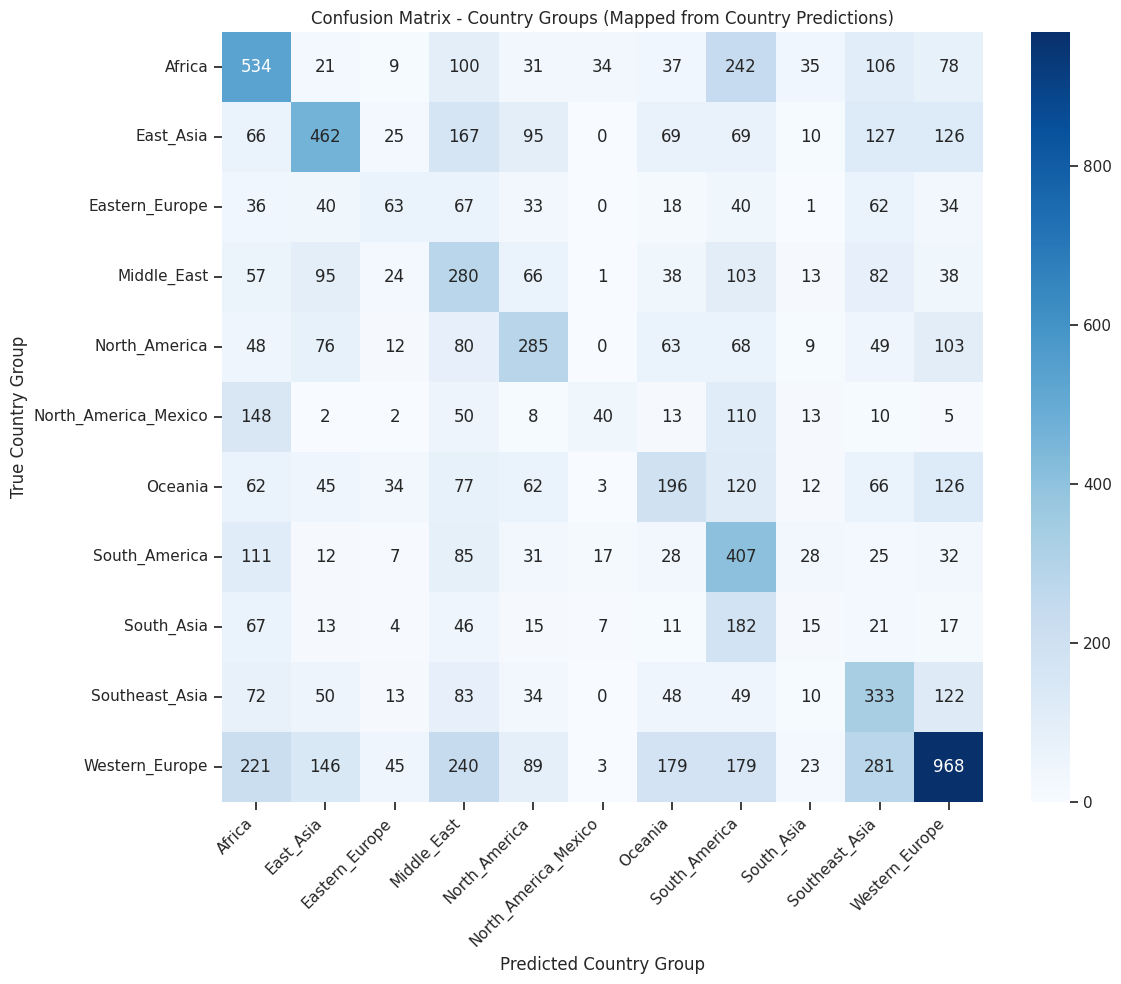


ACCURACY COMPARISON
Country-level accuracy (25 classes):        0.2790 (27.90%)
Country group accuracy (11 classes, mapped): 0.3583 (35.83%)
Improvement from aggregation:               7.93 percentage points

PER-GROUP ACCURACY BREAKDOWN
Africa                   : 43.52% ( 534/1227)
East_Asia                : 37.99% ( 462/1216)
Eastern_Europe           : 15.99% (  63/ 394)
Middle_East              : 35.13% ( 280/ 797)
North_America            : 35.94% ( 285/ 793)
North_America_Mexico     : 9.98% (  40/ 401)
Oceania                  : 24.41% ( 196/ 803)
South_America            : 51.98% ( 407/ 783)
South_Asia               : 3.77% (  15/ 398)
Southeast_Asia           : 40.91% ( 333/ 814)
Western_Europe           : 40.78% ( 968/2374)

VERIFICATION: Check if mapping is correct
✅ All countries are correctly mapped!

Current mapping:
  Argentina                 → South_America
  Australia                 → Oceania
  Brazil                    → South_America
  Canada                    → No

In [43]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ==========================================
# 1. DEFINE COUNTRY TO COUNTRY_GROUP MAPPING
# ==========================================
country_to_group_mapping = {
    # North America
    'United States': 'North_America',
    'Canada': 'North_America',
    
    # North America - Mexico
    'Mexico': 'North_America_Mexico',
    
    # Western Europe
    'Germany': 'Western_Europe',
    'France': 'Western_Europe',
    'United Kingdom': 'Western_Europe',
    'Netherlands': 'Western_Europe',
    'Spain': 'Western_Europe',
    'Italy': 'Western_Europe',
    
    # Eastern Europe
    'Russia': 'Eastern_Europe',
    
    # East Asia
    'China': 'East_Asia',
    'Japan': 'East_Asia',
    'South Korea': 'East_Asia',
    
    # Southeast Asia
    'Thailand': 'Southeast_Asia',
    'Singapore': 'Southeast_Asia',
    
    # Middle East
    'United Arab Emirates': 'Middle_East',
    'Turkey': 'Middle_East',
    
    # Africa
    'Egypt': 'Africa',
    'Nigeria': 'Africa',
    'South Africa': 'Africa',
    
    # Oceania
    'Australia': 'Oceania',
    'New Zealand': 'Oceania',
    
    # South America
    'Brazil': 'South_America',
    'Argentina': 'South_America',
    
    # South Asia
    'India': 'South_Asia'
}

# ==========================================
# 2. GET PREDICTIONS (assume you already have these)
# ==========================================
# Make predictions on test set
y_pred_proba = model.predict(X_test_scaled)
y_pred_country_encoded = np.argmax(y_pred_proba, axis=1)

# Convert encoded predictions back to country names
y_pred_country_names = le_target.inverse_transform(y_pred_country_encoded)

# Also get true country names
y_test_country_names = le_target.inverse_transform(y_test_encoded)

print("Sample predictions (first 10):")
print("Predicted countries:", y_pred_country_names[:10])
print("True countries:", y_test_country_names[:10])

# ==========================================
# 3. MAP COUNTRIES TO COUNTRY GROUPS
# ==========================================
# Map predicted countries to country groups
y_pred_country_groups = [country_to_group_mapping[country] for country in y_pred_country_names]

# Map true countries to country groups
y_test_country_groups = [country_to_group_mapping[country] for country in y_test_country_names]

print("\nSample mappings (first 10):")
for i in range(10):
    print(f"Predicted: {y_pred_country_names[i]} → {y_pred_country_groups[i]} | "
          f"True: {y_test_country_names[i]} → {y_test_country_groups[i]}")

# ==========================================
# 4. EVALUATE COUNTRY_GROUP ACCURACY
# ==========================================
country_group_accuracy = accuracy_score(y_test_country_groups, y_pred_country_groups)

print("\n" + "="*60)
print("COUNTRY GROUP ACCURACY (after mapping from country predictions)")
print("="*60)
print(f"Accuracy: {country_group_accuracy:.4f} ({country_group_accuracy*100:.2f}%)")

# Classification report for country groups
unique_groups = sorted(set(y_test_country_groups))
print("\nCLASSIFICATION REPORT (Country Groups):")
print(classification_report(y_test_country_groups, y_pred_country_groups))

# ==========================================
# 5. CONFUSION MATRIX FOR COUNTRY GROUPS
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

cm_groups = confusion_matrix(y_test_country_groups, y_pred_country_groups, labels=unique_groups)

plt.figure(figsize=(12, 10))
sns.heatmap(cm_groups, annot=True, fmt='d', cmap='Blues', 
            xticklabels=unique_groups, yticklabels=unique_groups)
plt.title('Confusion Matrix - Country Groups (Mapped from Country Predictions)')
plt.xlabel('Predicted Country Group')
plt.ylabel('True Country Group')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ==========================================
# 6. COMPARISON: COUNTRY vs COUNTRY_GROUP ACCURACY
# ==========================================
country_accuracy = accuracy_score(y_test_country_names, y_pred_country_names)

print("\n" + "="*60)
print("ACCURACY COMPARISON")
print("="*60)
print(f"Country-level accuracy (25 classes):        {country_accuracy:.4f} ({country_accuracy*100:.2f}%)")
print(f"Country group accuracy (11 classes, mapped): {country_group_accuracy:.4f} ({country_group_accuracy*100:.2f}%)")
print(f"Improvement from aggregation:               {(country_group_accuracy - country_accuracy)*100:.2f} percentage points")

# ==========================================
# 7. PER-GROUP ACCURACY BREAKDOWN
# ==========================================
print("\n" + "="*60)
print("PER-GROUP ACCURACY BREAKDOWN")
print("="*60)

from collections import defaultdict

group_correct = defaultdict(int)
group_total = defaultdict(int)

for true_group, pred_group in zip(y_test_country_groups, y_pred_country_groups):
    group_total[true_group] += 1
    if true_group == pred_group:
        group_correct[true_group] += 1

for group in sorted(unique_groups):
    acc = group_correct[group] / group_total[group] if group_total[group] > 0 else 0
    print(f"{group:25s}: {acc:.2%} ({group_correct[group]:4d}/{group_total[group]:4d})")

# ==========================================
# 8. VERIFY MAPPING IS CORRECT
# ==========================================
print("\n" + "="*60)
print("VERIFICATION: Check if mapping is correct")
print("="*60)

# Check if all countries are mapped
all_countries_in_data = set(y_test_country_names) | set(y_pred_country_names)
unmapped_countries = all_countries_in_data - set(country_to_group_mapping.keys())

if unmapped_countries:
    print("⚠️  WARNING: The following countries are NOT in the mapping:")
    print(unmapped_countries)
else:
    print("✅ All countries are correctly mapped!")

# Show the mapping
print("\nCurrent mapping:")
for country, group in sorted(country_to_group_mapping.items()):
    print(f"  {country:25s} → {group}")


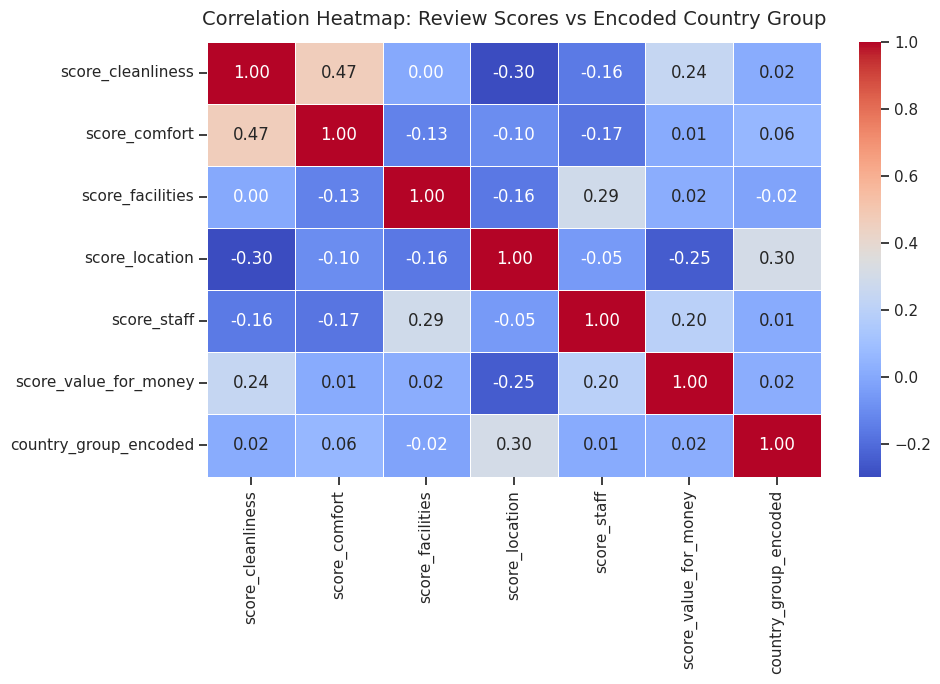

In [44]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

# Define numerical feature list
num_features = [
    'score_cleanliness', 'score_comfort', 'score_facilities',
    'score_location', 'score_staff', 'score_value_for_money'
]

# Copy your dataset
corr_df = merged_df.copy()

# Encode target if it’s not numeric
if corr_df['country_group'].dtype == 'object':
    le = LabelEncoder()
    corr_df['country_group_encoded'] = le.fit_transform(corr_df['country_group'])
else:
    corr_df['country_group_encoded'] = corr_df['country_group']

# Define features to include
features_corr = num_features + ['country_group_encoded']

# Compute correlation matrix
corr_matrix = corr_df[features_corr].corr()

# Set up figure
plt.figure(figsize=(10, 7))

# Plot correlation heatmap
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    cbar=True
)

plt.title("Correlation Heatmap: Review Scores vs Encoded Country Group", fontsize=14, pad=12)
plt.tight_layout()
plt.show()


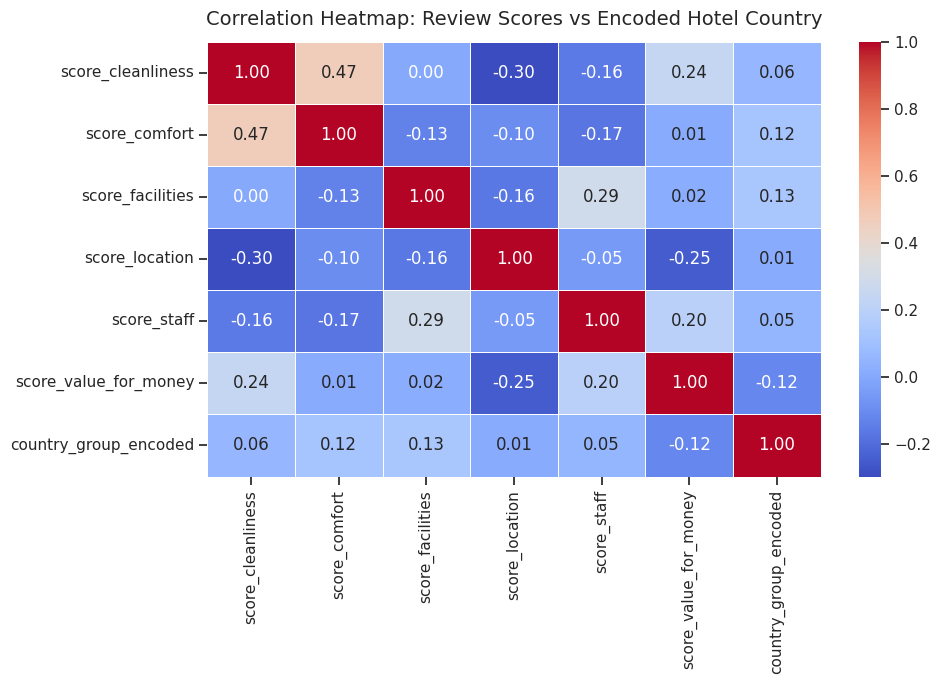

In [45]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

# Define numerical feature list
num_features = [
    'score_cleanliness', 'score_comfort', 'score_facilities',
    'score_location', 'score_staff', 'score_value_for_money'
]

# Copy your dataset
corr_df = merged_df.copy()

# Encode target if it’s not numeric
if corr_df['hotel_country'].dtype == 'object':
    le = LabelEncoder()
    corr_df['country_group_encoded'] = le.fit_transform(corr_df['hotel_country'])
else:
    corr_df['country_group_encoded'] = corr_df['hotel_country']

# Define features to include
features_corr = num_features + ['country_group_encoded']

# Compute correlation matrix
corr_matrix = corr_df[features_corr].corr()

# Set up figure
plt.figure(figsize=(10, 7))

# Plot correlation heatmap
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    cbar=True
)

plt.title("Correlation Heatmap: Review Scores vs Encoded Hotel Country", fontsize=14, pad=12)
plt.tight_layout()
plt.show()


In [46]:
!pip install scipy seaborn


In [47]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# Function to compute Cramér’s V
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    return np.sqrt((chi2 / n) / (min(k-1, r-1)))


In [48]:
categorical_cols = ['user_traveller_type', 'hotel_city', 'hotel_country', 'user_gender', 'user_age_group' ]  # your categorical cols
target_col = 'country_group'

cramers_results = {}

for col in categorical_cols:
    cramers_results[col] = cramers_v(merged_df[col], merged_df[target_col])

cramers_df = pd.DataFrame.from_dict(cramers_results, orient='index', columns=['Cramers_V'])
print(cramers_df)


                     Cramers_V
user_traveller_type   0.014448
hotel_city            1.000000
hotel_country         1.000000
user_gender           0.014252
user_age_group        0.016290


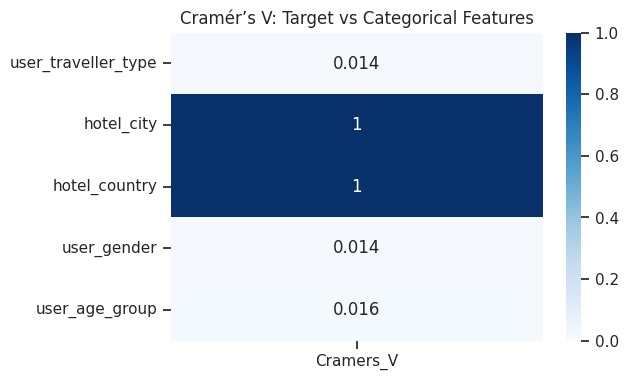

In [49]:
plt.figure(figsize=(6,4))
sns.heatmap(cramers_df, annot=True, cmap='Blues', vmin=0, vmax=1)
plt.title("Cramér’s V: Target vs Categorical Features")
plt.show()


valid and makes sense for the hotel country and city to be 100% related to country_group

In [50]:
############inference
import numpy as np

def compare_true_vs_pred(sample_index, X_test, y_test, model, scaler, label_encoder, feature_columns):
    # ---- 1) Get sample ----
    sample = X_test.iloc[sample_index:sample_index+1]         # one row (as DataFrame)
    sample_scaled = scaler.transform(sample[feature_columns]) # scale
    
    # ---- 2) True label ----
    true_country = y_test.iloc[sample_index]                  # already original label
    
    # ---- 3) Prediction ----
    probs = model.predict(sample_scaled)[0]
    pred_index = np.argmax(probs)
    pred_country = label_encoder.inverse_transform([pred_index])[0]
    
    # ---- 4) Print result ----
    print(f"\n━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━")
    print(f" Sample Index: {sample_index}")
    print(f"━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━")
    print(f"✔ TRUE Country      : {true_country}")
    print(f"✔ PREDICTED Country : {pred_country}")
    print(f"✔ Probabilities     : {probs}")
    print(f"━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━\n")

compare_true_vs_pred(
    sample_index=7,
    X_test=X_test,
    y_test=y_test,
    model=model,
    scaler=scaler,
    label_encoder=le_target,
    feature_columns=X_train.columns
)



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Sample Index: 7
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
✔ TRUE Country      : Germany
✔ PREDICTED Country : Singapore
✔ Probabilities     : [7.1709981e-04 1.5144708e-03 9.4567979e-05 7.0044003e-02 3.5741694e-02
 7.7135828e-06 2.5081519e-02 7.6548830e-02 2.6853598e-04 5.8471579e-02
 9.2711682e-03 7.6314200e-06 8.4413201e-02 7.8959063e-02 1.1207201e-08
 6.5381132e-02 9.2924751e-02 7.0550911e-02 7.6472588e-02 6.3939497e-02
 8.0606475e-02 1.2834248e-02 6.1695535e-02 3.4015957e-02 4.3780534e-04]
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

